# Max Loss Analysis for GemNet-OC Model 

In [1]:
import numpy as np 
from matplotlib import pyplot as plt

In [2]:
# distribution of atomic numbers 
loss_Z = np.load("loss-atomic_number.npy")

"""
# Get unique values and their counts
unique, counts = np.unique(loss_Z.round(3), return_counts=True)

plt.figure(dpi=400)
plt.bar(unique, counts, edgecolor='black')
plt.xticks(unique, rotation=90)   # force each unique value to appear
plt.tight_layout()
plt.show()
"""


"\n# Get unique values and their counts\nunique, counts = np.unique(loss_Z.round(3), return_counts=True)\n\nplt.figure(dpi=400)\nplt.bar(unique, counts, edgecolor='black')\nplt.xticks(unique, rotation=90)   # force each unique value to appear\nplt.tight_layout()\nplt.show()\n"

Text(0.5, 1.0, 'Frequency of Errors > 0.01 by Atom Tag')

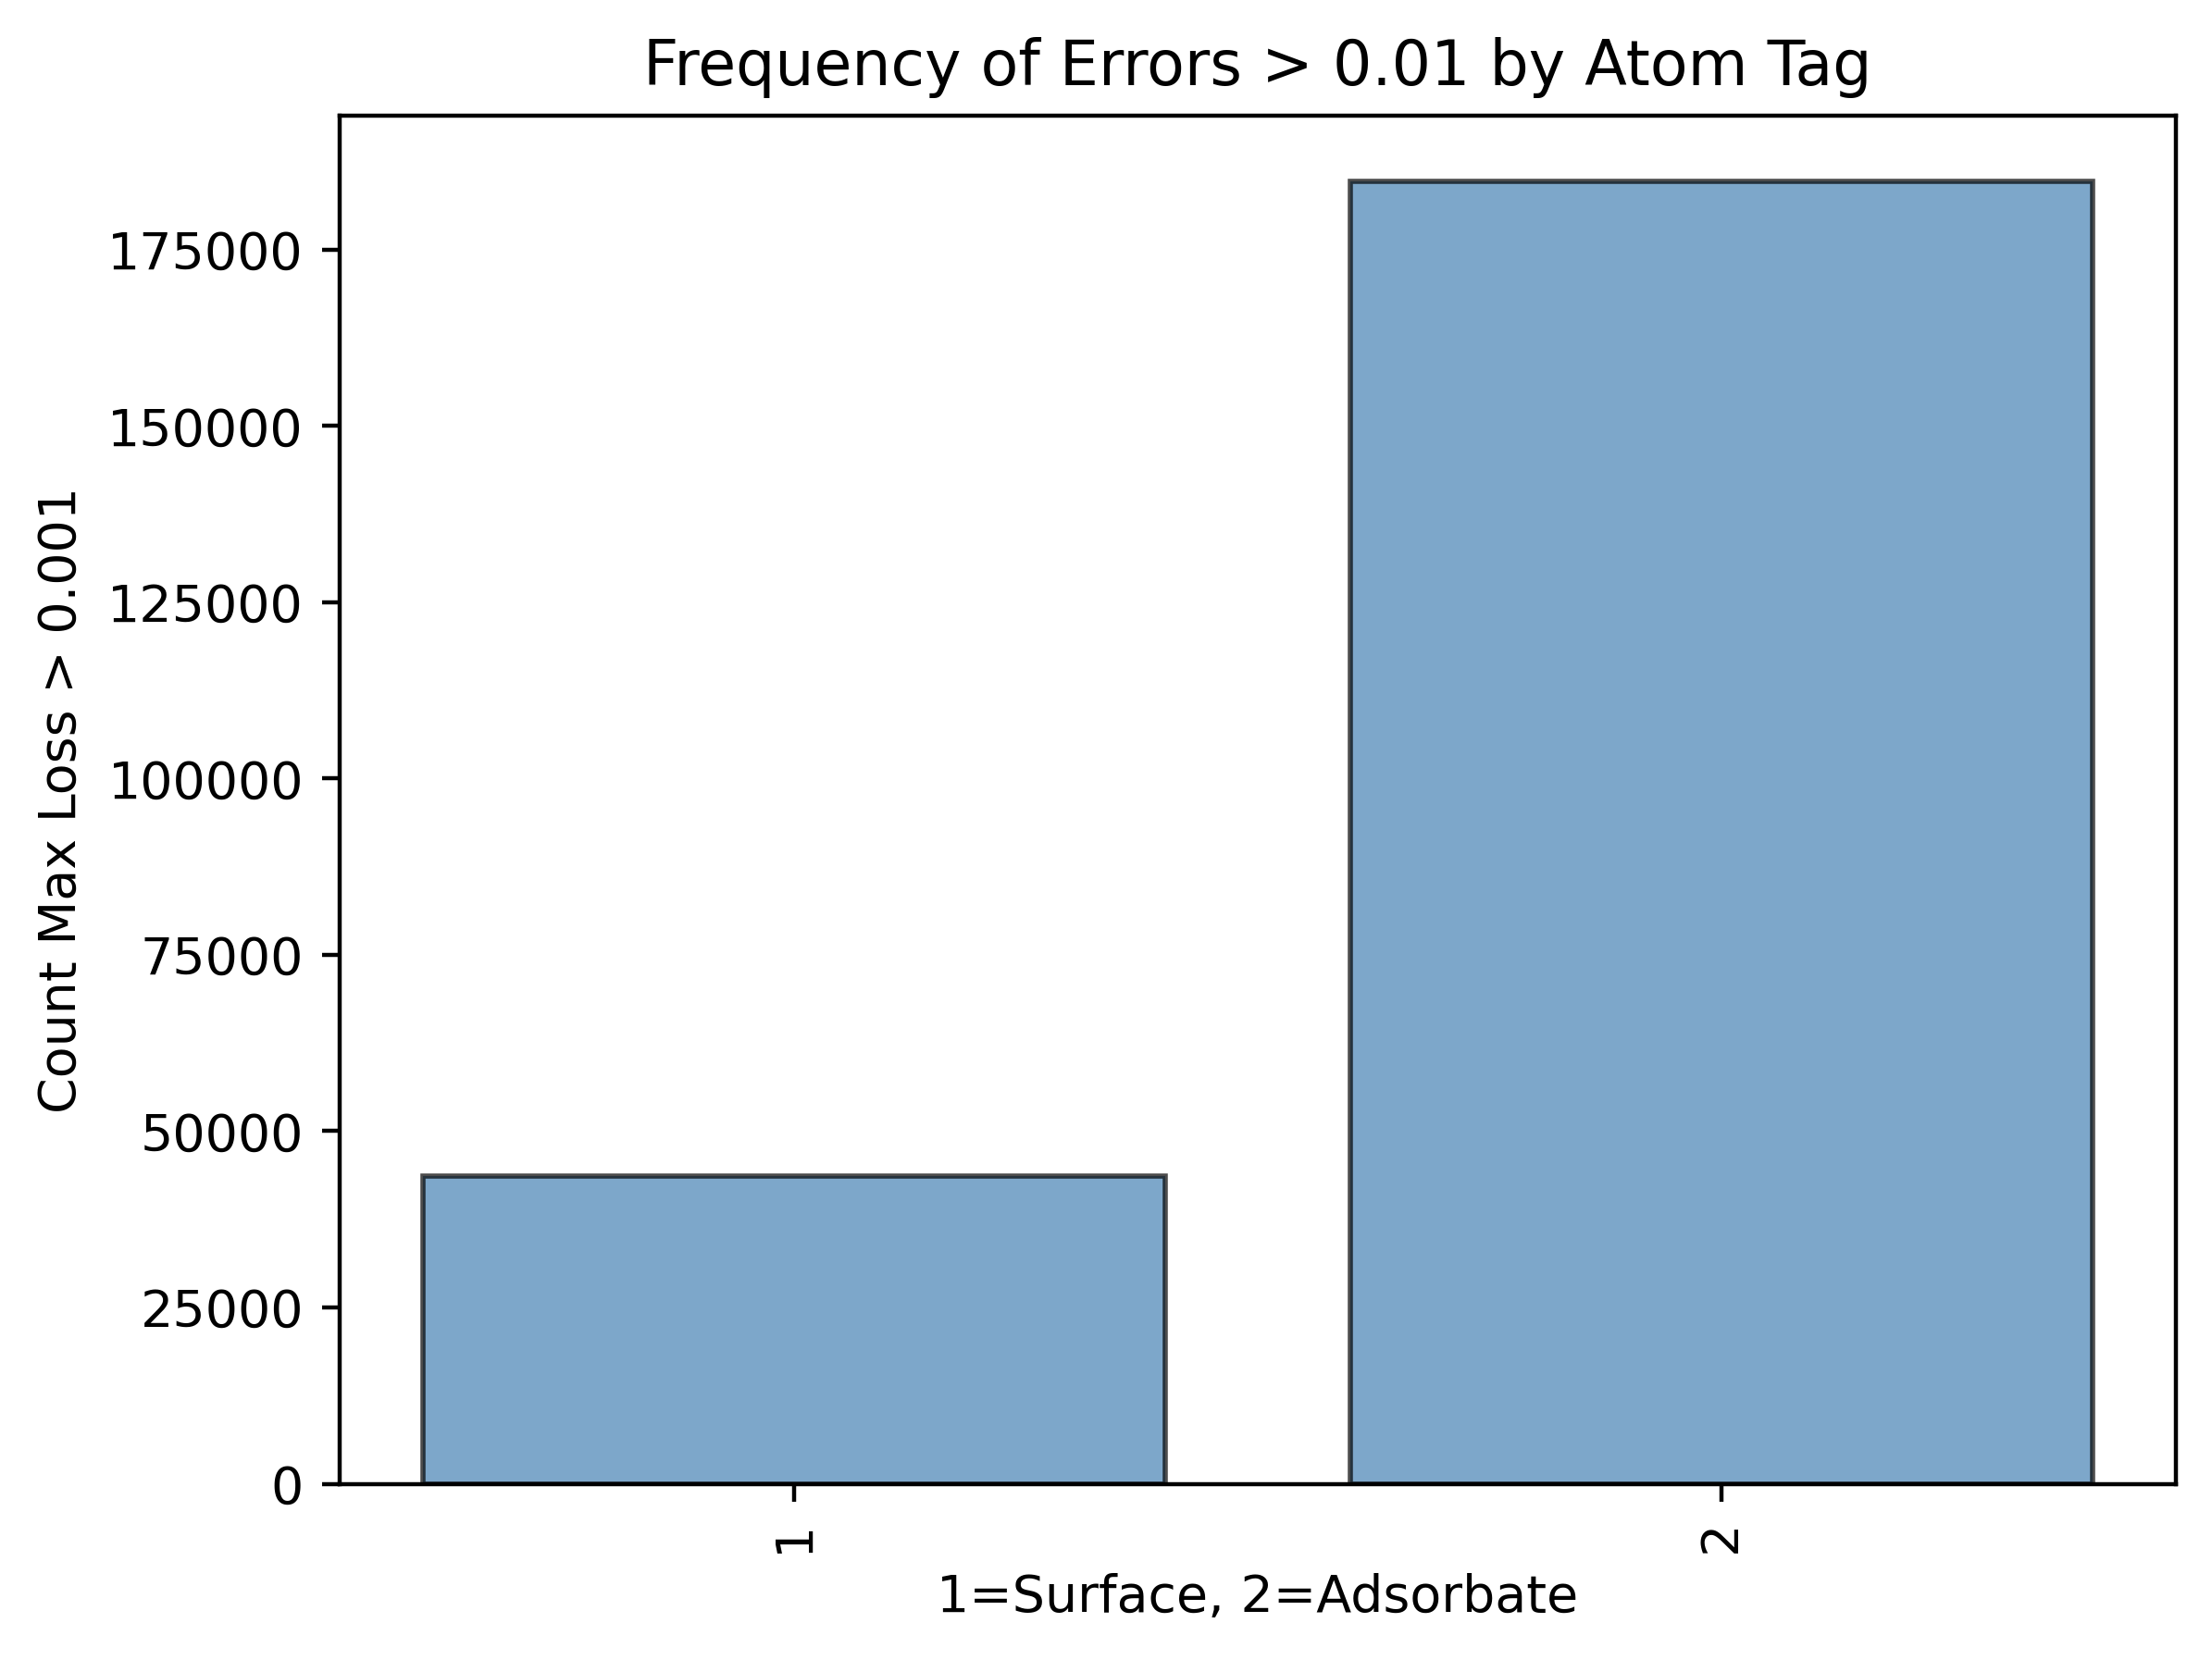

In [5]:
# distribution of tags (1 -> surface atom, 2 -> adsorbate atom)
loss_tag = np.load("loss-tag.npy")

# Get unique values and their counts
unique, counts = np.unique(loss_tag, return_counts=True)

plt.figure(dpi=400)
plt.bar(unique, counts, edgecolor='black', color='steelblue', alpha=0.7)
plt.xticks(unique, rotation=90)   # force each unique value to appear
plt.xlabel("1=Surface, 2=Adsorbate")
plt.ylabel("Count Max Loss > 0.001")
plt.title('Frequency of Errors > 0.01 by Atom Tag')

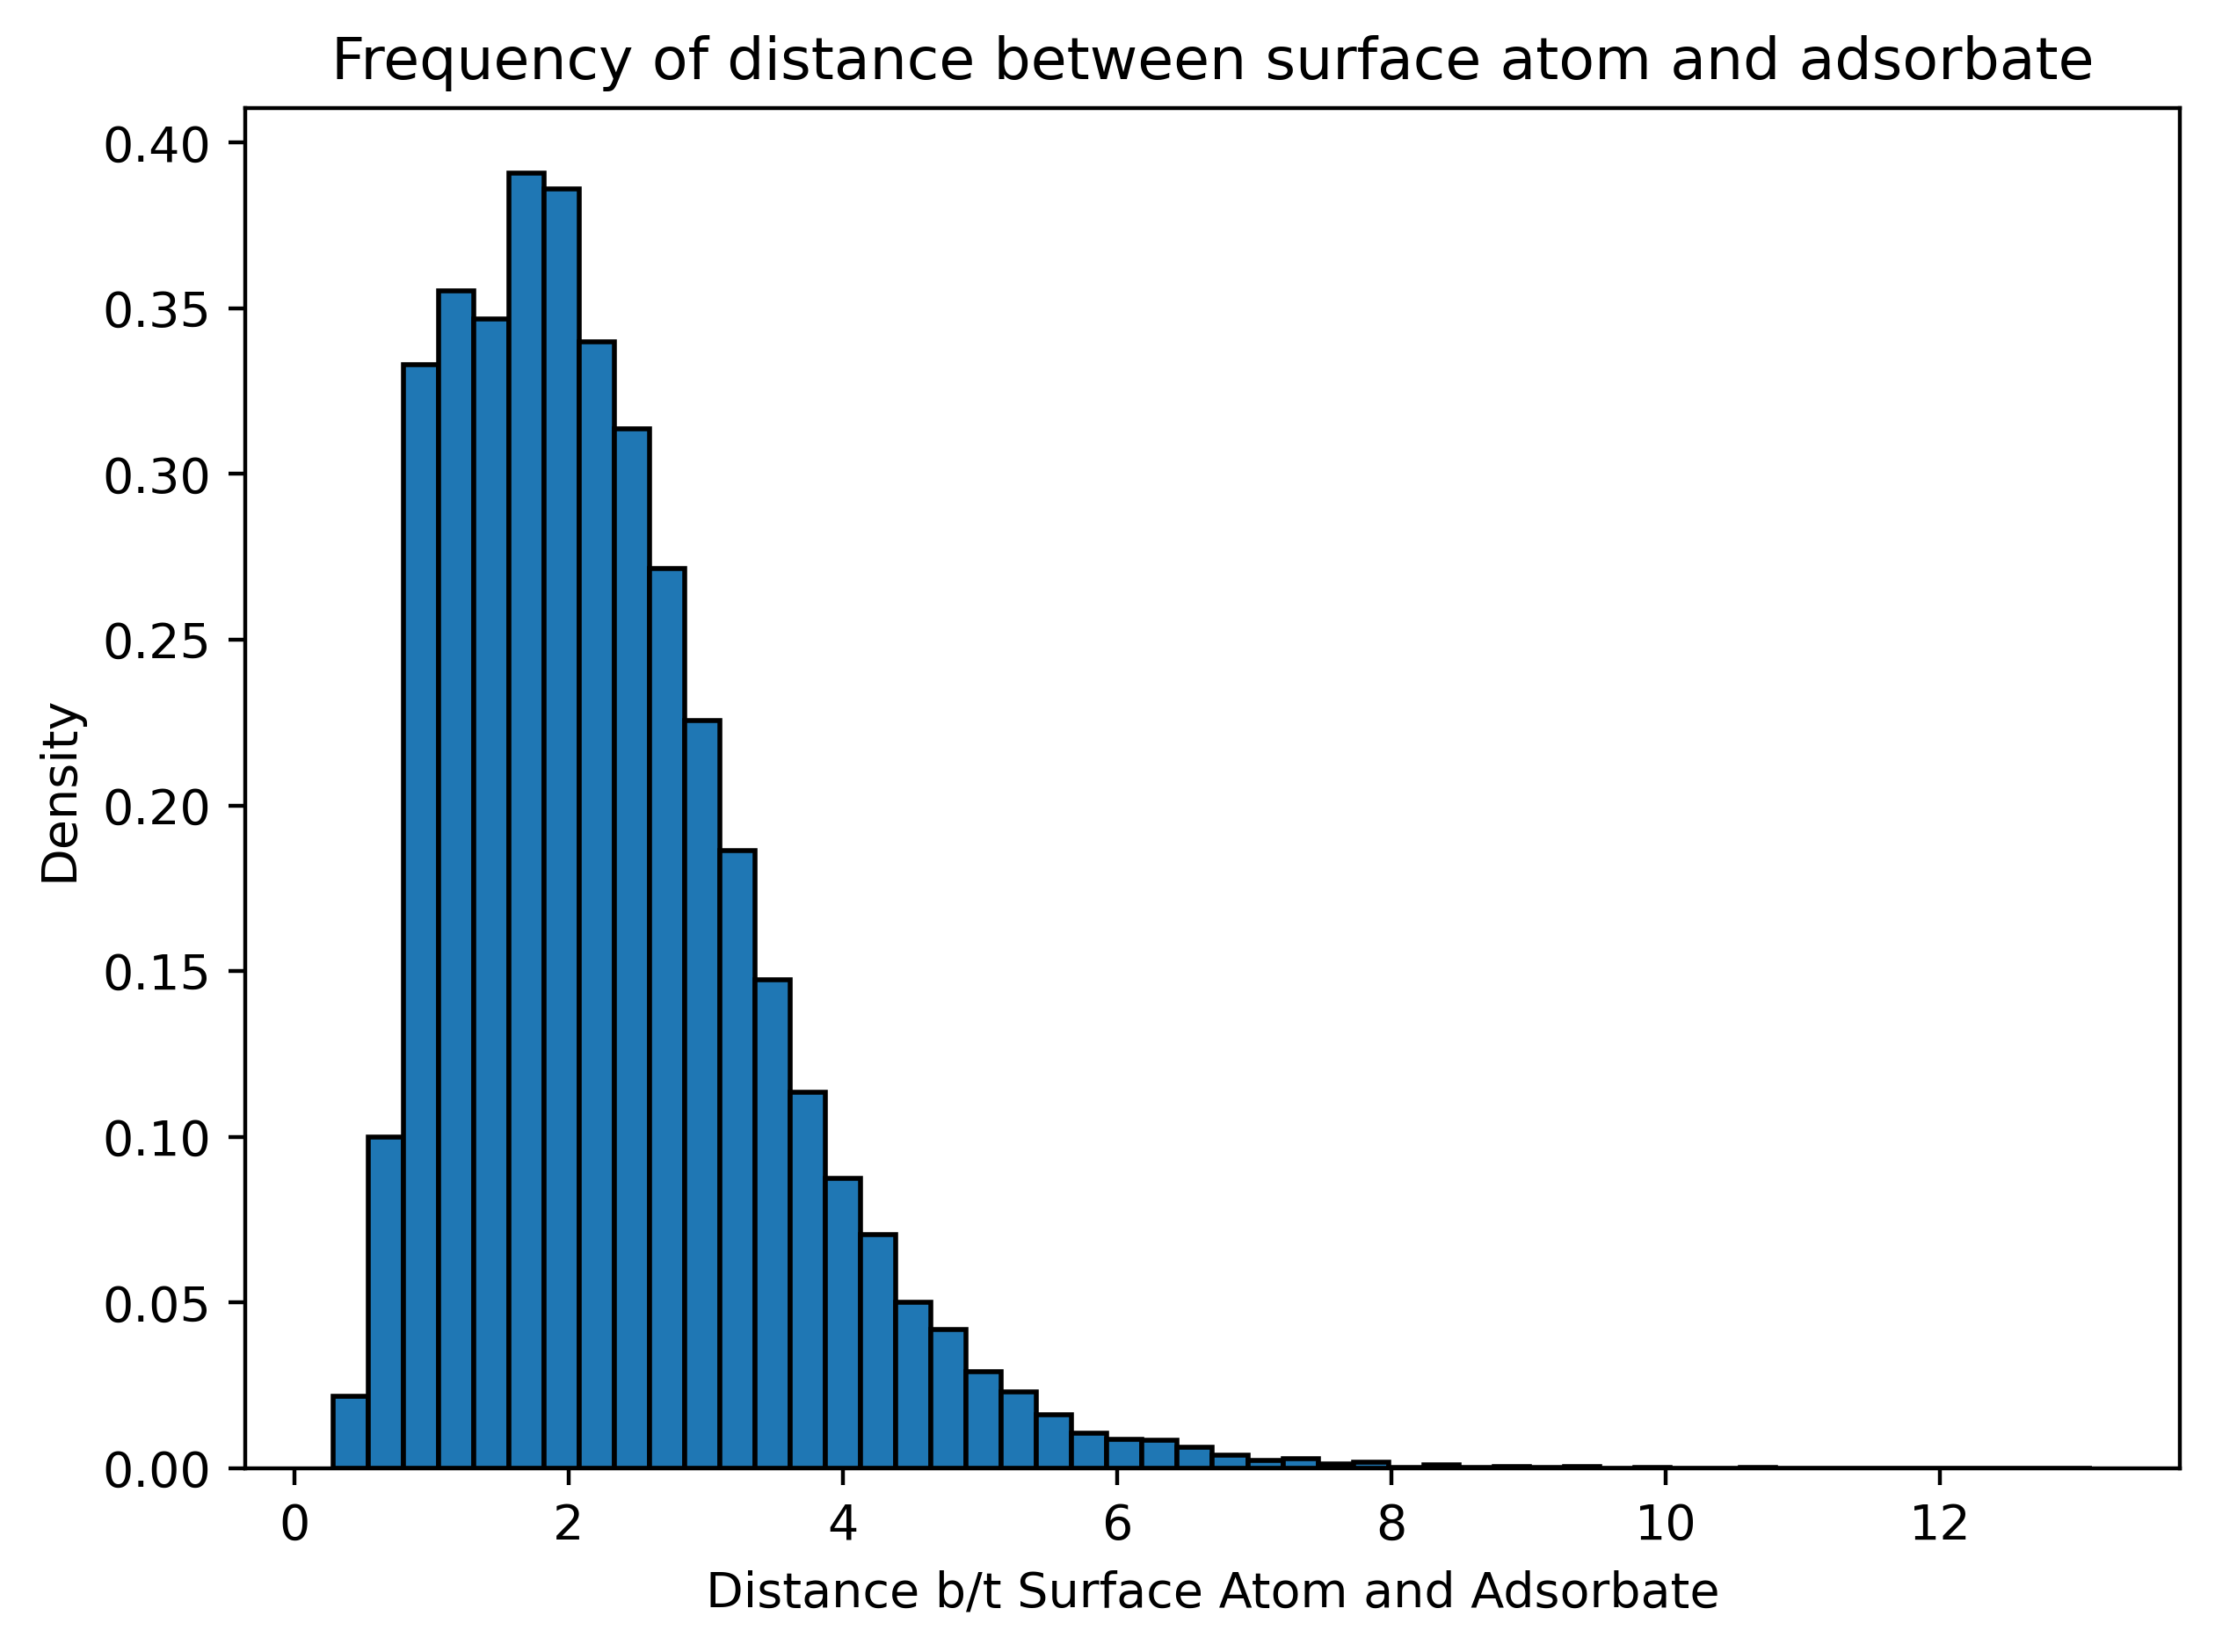

In [13]:
# distribution of atomic distance between surface atom and adsorbate 
loss_displacement = np.load("loss-displacement_from_ads.npy")

plt.figure(dpi=400)
plt.hist(loss_displacement, density=True,  bins=50, edgecolor='black')
plt.xlabel('Distance b/t Surface Atom and Adsorbate')
plt.ylabel('Density')
plt.title('Frequency of distance between surface atom and adsorbate')
plt.tight_layout()

Linear Regression Results:
Slope: 0.7257
Intercept: -0.1586
R²: 0.4384
p-value: 0.0000e+00


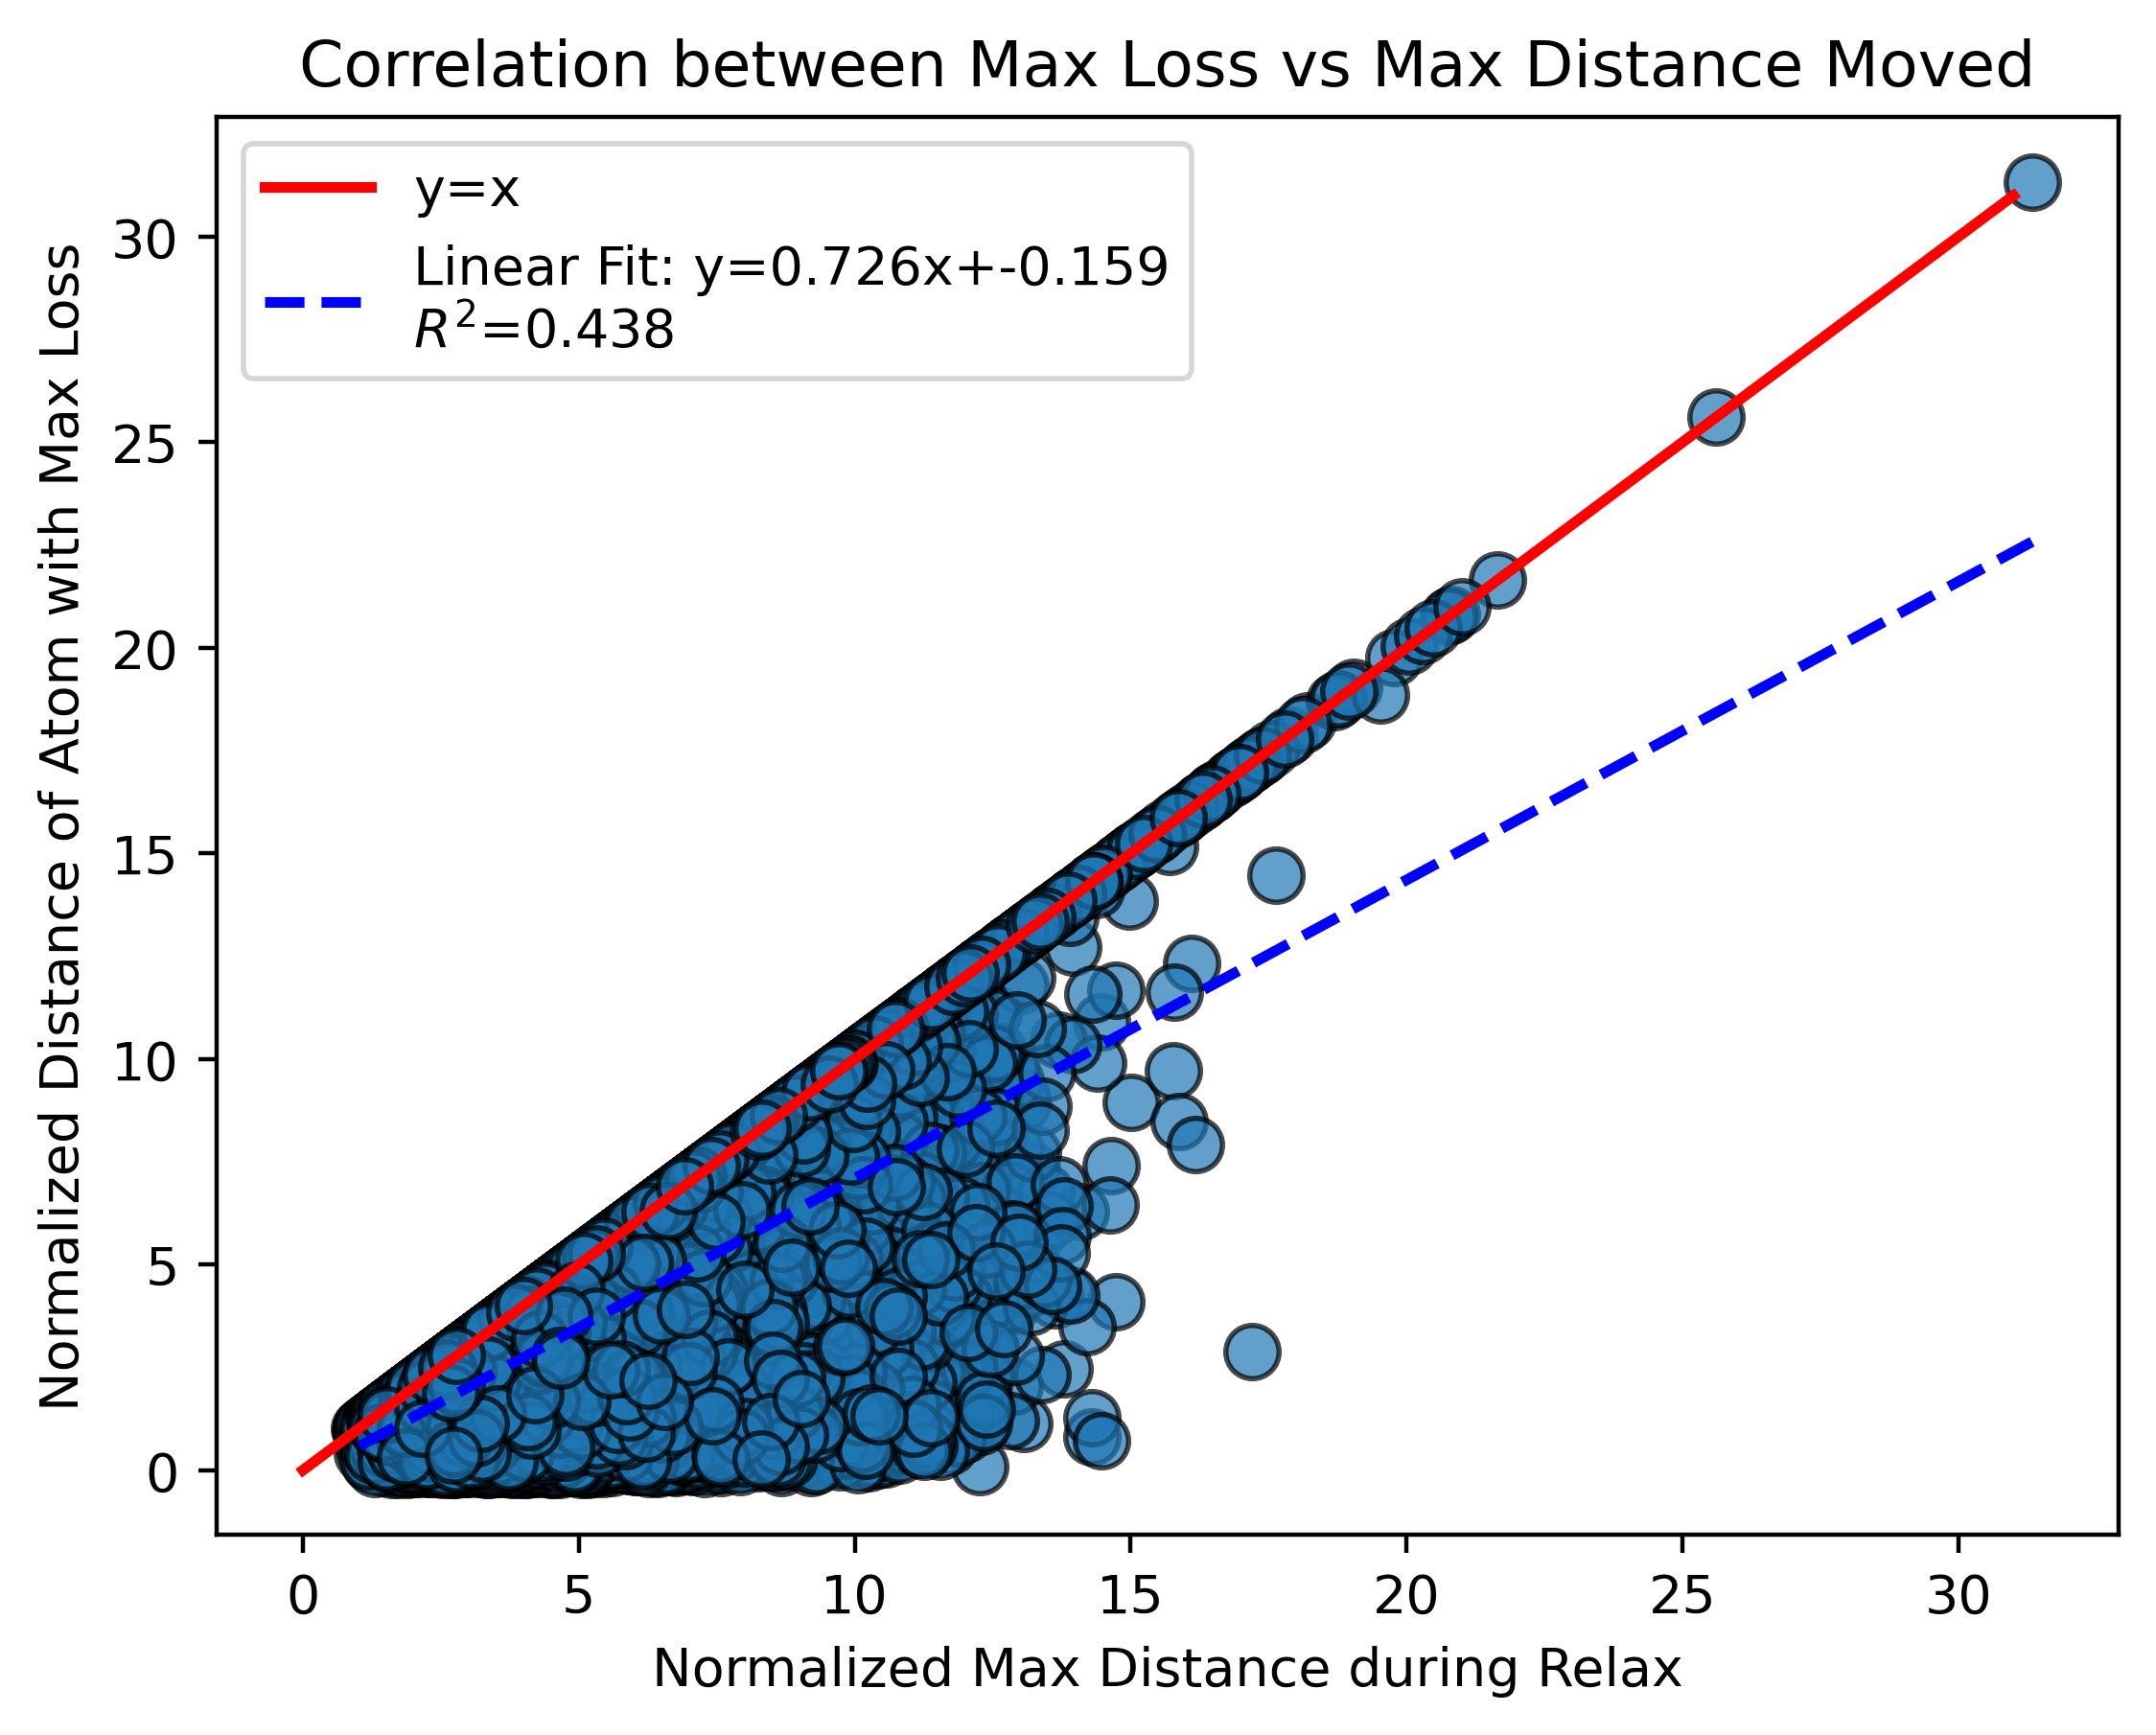

In [14]:
from scipy import stats

distance_max = np.load("distance-max.npy")
#distance_max = distance_max[::2] # remove duplicate elements 
distance_max_loss = np.load("distance-max_loss.npy")
#distance_max_loss = distance_max_loss[::2] # remove duplicate elements 
distance_avg = np.load("avg_distance.npy")

# Normalize by average movement of all atoms 
norm_distance_max = distance_max / distance_avg
norm_distance_max_loss = distance_max_loss / distance_avg

# Compute linear regression
slope, intercept, r_value, p_value, std_err = stats.linregress(norm_distance_max, norm_distance_max_loss)
r_squared = r_value**2

# Generate regression line
x_reg = np.linspace(norm_distance_max.min(), norm_distance_max.max(), 100)
y_reg = slope * x_reg + intercept

plt.figure(dpi=400)
x = np.arange(0, 32)
plt.plot(x, x, color="red", label="y=x", linewidth=2)
plt.scatter(
    norm_distance_max,
    norm_distance_max_loss,
    s=100,      # or e.g. 5 + 3*counts to exaggerate
    alpha=0.7,
    edgecolors="black"
)
plt.plot(x_reg, y_reg, color="blue", linewidth=2, linestyle="--", 
         label=f"Linear Fit: y={slope:.3f}x+{intercept:.3f}\n$R^2$={r_squared:.3f}")
plt.xlabel("Normalized Max Distance during Relax")
plt.ylabel("Normalized Distance of Atom with Max Loss")
plt.title("Correlation between Max Loss vs Max Distance Moved")
plt.legend()

print(f"Linear Regression Results:")
print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"R²: {r_squared:.4f}")
print(f"p-value: {p_value:.4e}")

## Analysis 
- The x-axis is the max distance moved during a relaxation. The y-axis is the max distance moved of the atom with the maximum velocity field loss. Both are normalized by the average distance moved of all atoms in the structure (excluding frozen atoms).  

- Poor correlation between these two metrics, indicating that atoms with high velocity field losses are not always the atoms that move the most during a relaxation. 

- BUT... this may just be a difficult correlation to prove so lets just consider how much atoms with max lossses move relative to the entire structure (excluding frozen atoms). 

Total samples: 228346
Values below 1: 26244 (11.49%)


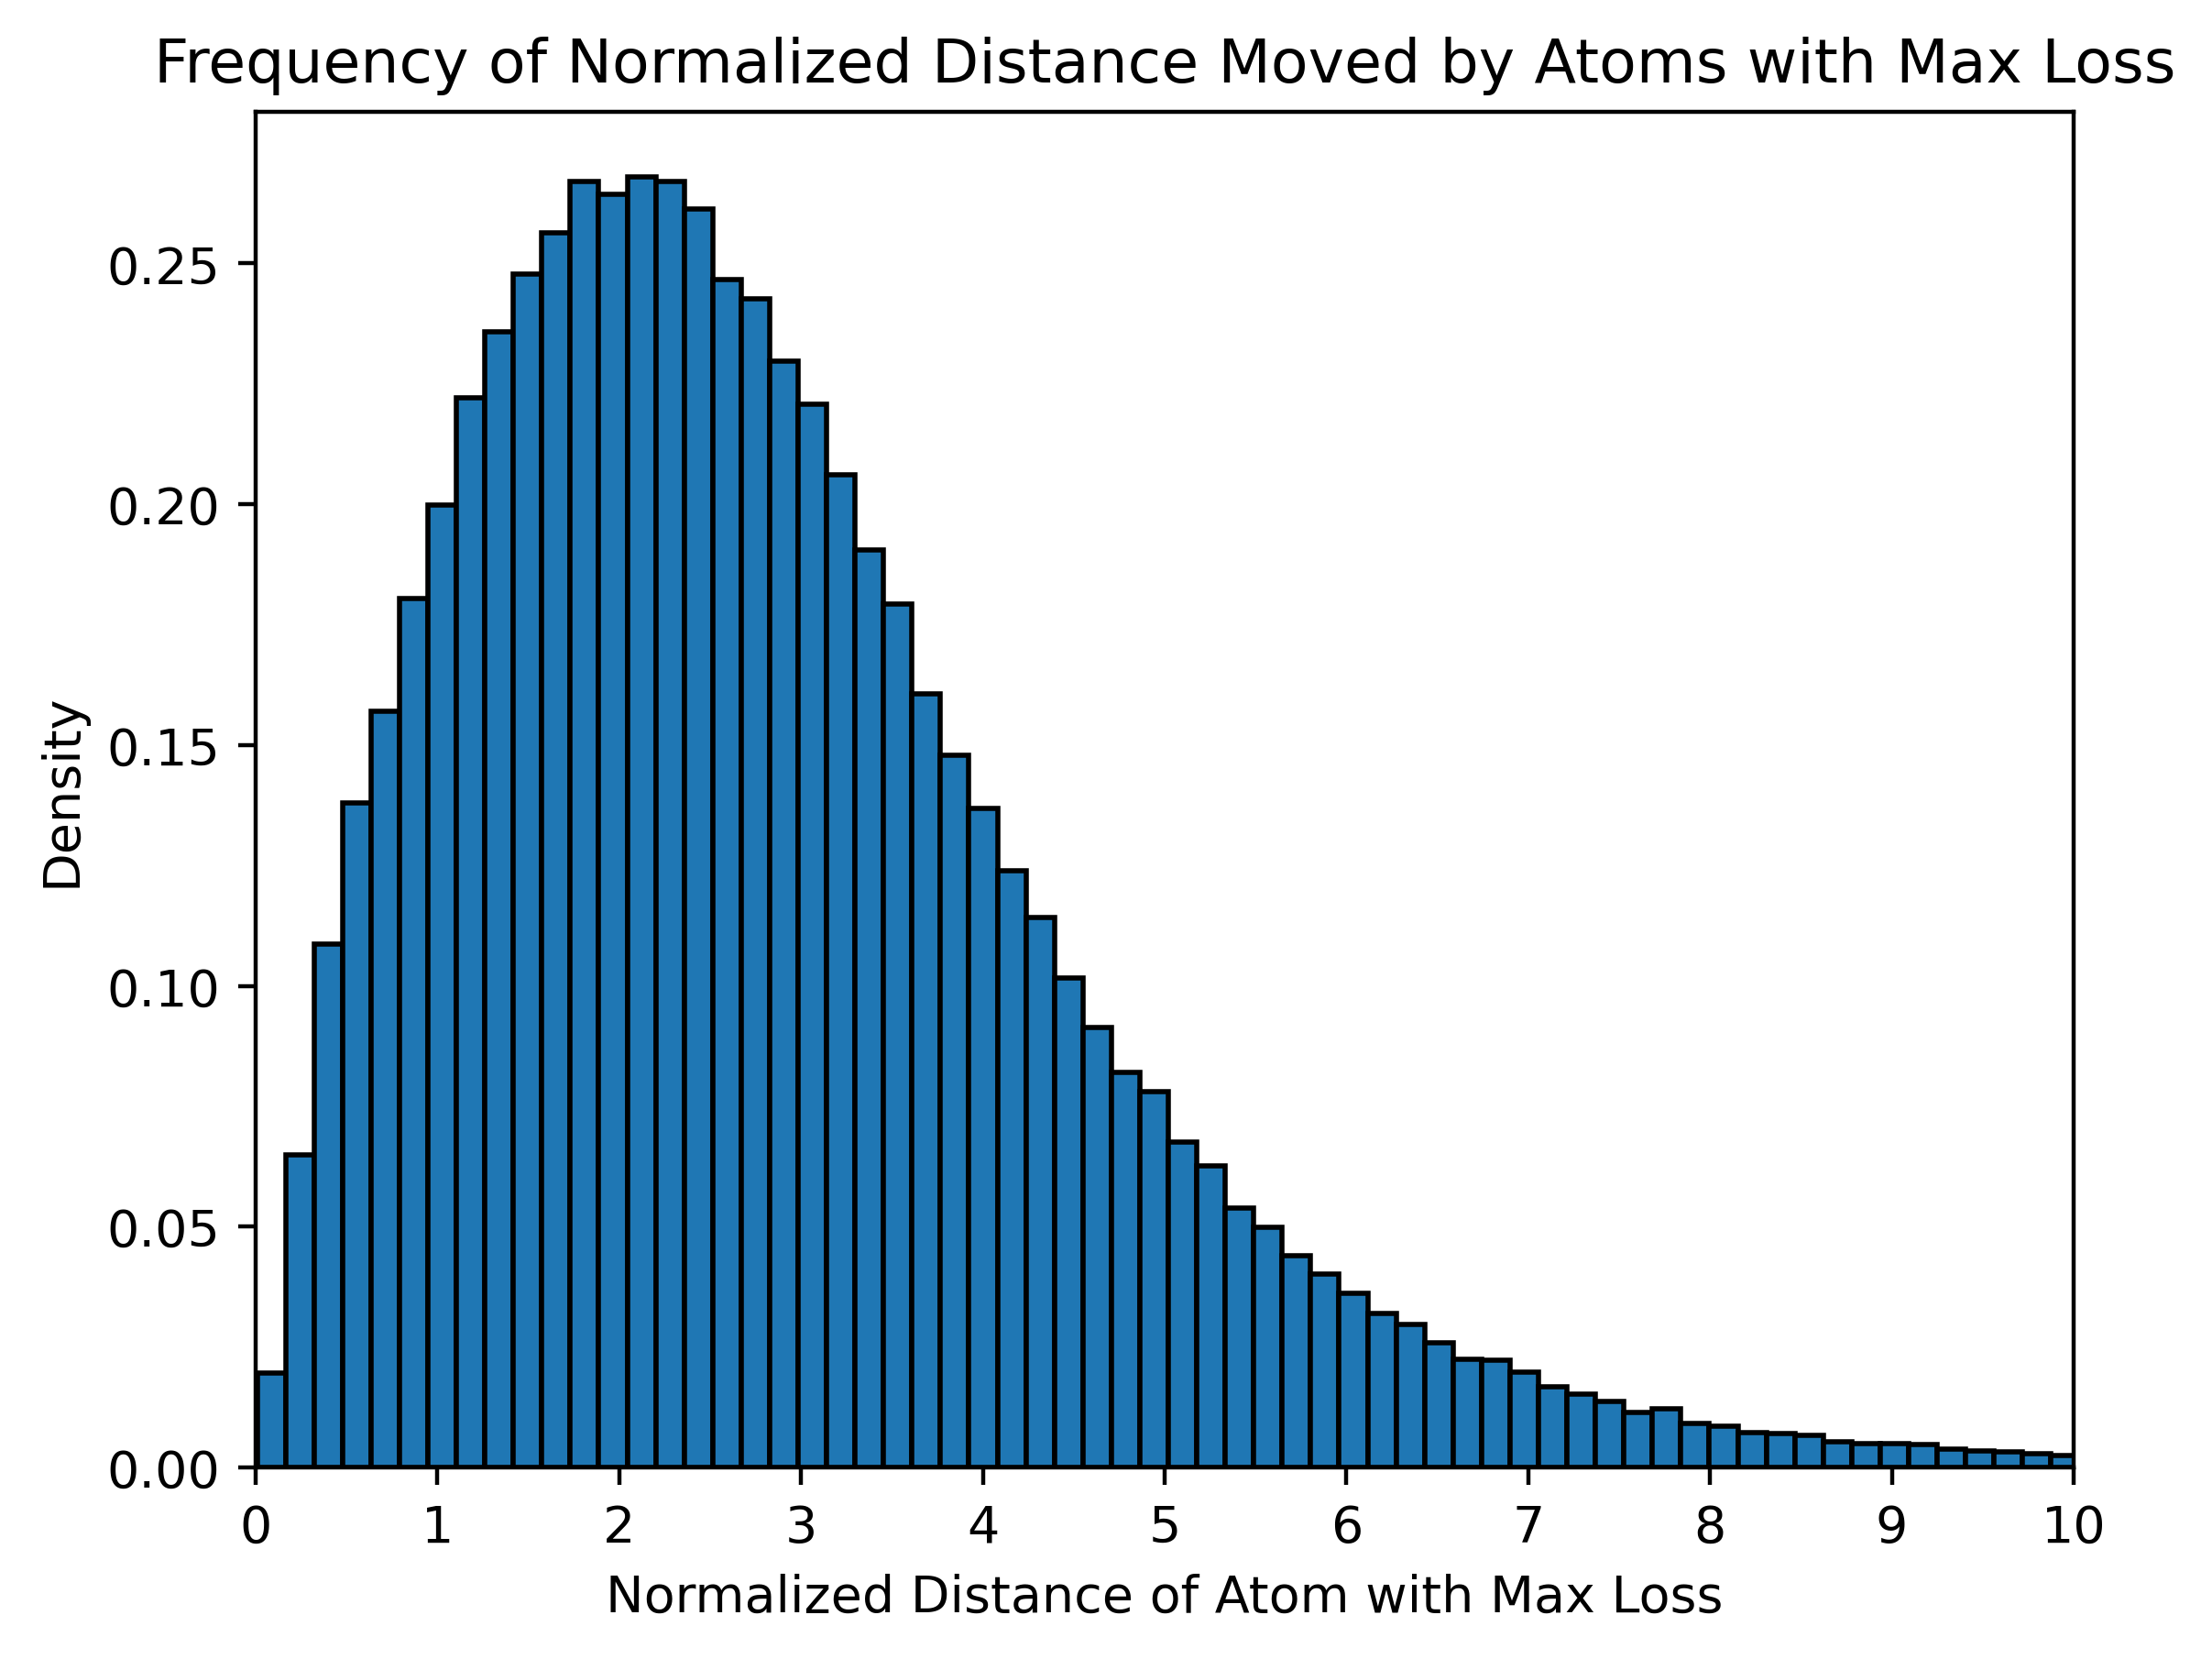

In [15]:
plt.figure(dpi=400)
plt.hist(norm_distance_max_loss, bins=200, density=True, edgecolor='black')
plt.xlabel("Normalized Distance of Atom with Max Loss")
plt.ylabel('Density')
plt.xlim(0, 10)  # Focus on the main range
plt.xticks(np.arange(0, 11, 1))
plt.title('Frequency of Normalized Distance Moved by Atoms with Max Loss')

# Summary statistics for values below 1
below_one = norm_distance_max_loss < 1
print(f"Total samples: {len(norm_distance_max_loss)}")
print(f"Values below 1: {np.sum(below_one)} ({100*np.mean(below_one):.2f}%)")


# Conclusions & Final Thoughts
- Atoms with high velocity field losses dre largely the adsorbate atom or surface atoms within 3A of the adsobate atom. 

- Atoms with these high losses move on average more than most atoms in the structure, BUT they are not necessarily the atom that moves the most during a relaxation. This does not mean that the velocity field loss does not correlate with better structures. Empirically, the lower we get the loss function, the better our structures look. 

- I did the same analysis on EquV2 and the conclusions hold.

- Instead of just counting the atoms that have the max loss within a structure, I should also examine all atoms within a structure above the 0.001 A^2 threshold and see if the trends hold. Thoughts?

- I am doing further analysis by computing (with DFT) and comparing  the energy and forces of an inputted structure, a generated structure, and a relaxed structure. I just finished the pipeline from our model to DFT. 

- At this point, I am going to implemenent three different modified loss functions and observe what works best: 
    1. Weight atoms by their distance moved during a relaxation. 

    2. Weight the adsorbate atoms more than surface atoms. 
    
    3. Weight adsorbate atoms and surface atoms within some cutoff.  



In [4]:
# distribution of atomic distance between surface atom and adsorbate 
relaxed_E = np.load("relaxed_E.npy") 
inputted_E = np.load("inputted_E.npy") 

inputted_error = np.abs(relaxed_E - inputted_E)
inputted_error = np.nan_to_num(inputted_error, nan=1)

print("Error on Pre-Relaxed Structures: ")
print("================================")
print(f"Average error: {np.mean(inputted_error)} \nMedian error: {np.median(inputted_error)}  \nMax error: {np.max(inputted_error)} \nMin error: {np.min(inputted_error)}")


Error on Pre-Relaxed Structures: 
Average error: 1020.295148785 
Median error: 5.6179028900000105  
Max error: 36186.344021640005 
Min error: 0.2052722899999999


In [5]:
generated_E = np.load("generated_E.npy")
generated_error = np.abs(relaxed_E - generated_E)
generated_error = np.nan_to_num(generated_error, nan=1)

print("Error on Generated Structures: ")
print("================================")
print(f"Average error: {np.mean(generated_error)} \nMedian error: {np.median(generated_error)} \nMax error: {np.max(generated_error)}, \nMin error: {np.min(generated_error)}")

Error on Generated Structures: 
Average error: 731.5947148667001 
Median error: 1.0 
Max error: 33362.7930617, 
Min error: 0.005946989999999985
